# 03 · VLM analysis
Task-conditioned grounding, the VLM Task-Relevance Map and its comparison with gaze.

> **Prerequisite:** `python -m gazegrounded.cli run-all` (synthetic demo).
>
> All logic lives in `src/gazegrounded/`; this notebook only calls it. With the synthetic config every number is **SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE**.

The demo uses the **mock** provider (lexical, reads AOI annotations — not a VLM). Set `vlm.provider: local` to use Qwen2.5-VL.

In [1]:
from pathlib import Path
import os
# Run from the repository root so relative config paths resolve.
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")
import numpy as np
import pandas as pd
from gazegrounded.config import load_config
from gazegrounded.data.loader import load_processed
from gazegrounded.utils import SYNTHETIC_BANNER
cfg = load_config("configs/synthetic.yaml")  # switch to configs/experiment.yaml for real data
ds = load_processed(cfg)
print(SYNTHETIC_BANNER if ds.is_synthetic else "Real data:", cfg.data.source)

SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE synthetic


In [2]:
from gazegrounded.vlm.prompts import build_prompt
system, user = build_prompt('Change the delivery address for this order.', 'normalized')
print(user[:900])

The user's task is: "Change the delivery address for this order."

Analyze the user interface with respect to this task. Identify the visible interface elements
that are relevant to completing the task (at most 8). For each element estimate:
- task_relevance: how relevant it is for completing the task (0 = irrelevant, 1 = essential)
- expected_attention_priority: how much of a user's attention it should receive while pursuing
  this task (0 = none, 1 = the main focus)
and give its bounding box.

Give each bbox as fractions of the image width and height between 0 and 1 (x_min, y_min, x_max, y_max), with (0, 0) at the top-left corner.

Return ONLY a JSON object with exactly this structure (no markdown, no commentary):
{
  "task": "<the task>",
  "elements": [
    {
      "label": "Edit address",
      "semantic_role": "button",
      "task_relevance": 0.94,
      "expected_attention_priori


In [3]:
from gazegrounded.vlm.base import make_provider
provider = make_provider(cfg, ds)
task = ds.tasks.set_index('task_id').loc['bank_cards_friction__freeze_card']
analysis = provider.analyze_ui(ds.image_path(task.ui_id), task.task_description)
print(analysis.parse_status, 'from cache:', analysis.from_cache)
pd.DataFrame([{'label': e.label[:30], 'role': e.semantic_role, 'relevance': e.task_relevance, 'priority': e.expected_attention_priority} for e in analysis.elements])

ok from cache: True


,label,role,relevance,priority
0,Card type: Debit Mastercard. I,text,0.860,0.734
1,NordBank Debit **** 4821,image,0.645,0.642
2,icon_freeze,button,0.630,0.727
3,Debit card **** 4821,text,0.563,0.508
4,icon_more,button,0.277,0.333
5,Recent transactions,region,0.254,0.284
6,Upgrade to Platinum,banner,0.207,0.262
7,Overview,navigation,0.204,0.263


### Robust parsing
Malformed or differently formatted model output must not crash the pipeline.

In [4]:
from gazegrounded.vlm.grounding import parse_vlm_response
for raw in ['Sorry, I cannot help.', '```json\n[{"label": "Freeze", "bbox_2d": [720, 296, 950, 351], "relevance": 90}]\n```']:
    a = parse_vlm_response(raw, 'freeze', image_size=(1440, 900))
    print(a.parse_status, [(e.label, e.bbox.as_tuple()) for e in a.elements], a.warnings)

failed [] ['no parseable JSON object found in model output']
ok [('Freeze', (0.5, 0.3288888888888889, 0.6597222222222222, 0.39))] []


{'cc': 0.755, 'spearman': 0.572, 'cosine': 0.809, 'sim': 0.604, 'kl': 0.704, 'jsd': 0.198}


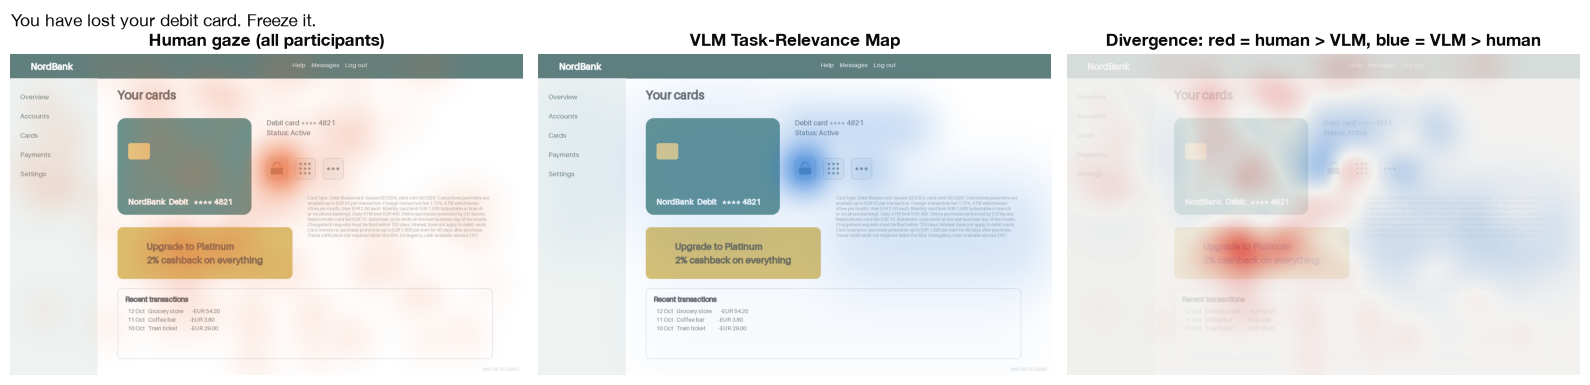

In [5]:
%matplotlib inline
from gazegrounded.pipeline import load_fixations, load_vlm_maps, task_human_map
from gazegrounded.analysis.saliency_metrics import compare_maps
from gazegrounded.visualization.comparisons import human_vs_vlm_figure
from gazegrounded.visualization.gaze import load_image
fix, maps = load_fixations(cfg), load_vlm_maps(cfg)
human, _ = task_human_map(cfg, ds, fix, 'bank_cards_friction__freeze_card')
m = compare_maps(human, maps['bank_cards_friction__freeze_card'])
print({k: round(v, 3) for k, v in m.items()})
fig = human_vs_vlm_figure(load_image(ds.image_path(task.ui_id)), human, maps['bank_cards_friction__freeze_card'], task.task_description)

### Why the early-window divergence is primary
Whole-trial JSD between a sparse gaze map and a smooth VLM map is inflated for short trials.

In [6]:
feat = pd.read_csv(cfg.processed_dir() / 'features.csv')
feat[['attention_divergence','attention_divergence_early','fixation_count','completion_time_ms']].corr(method='spearman').round(2)

,attention_divergence,attention_divergence_early,fixation_count,completion_time_ms
attention_divergence,1.00,0.40,-0.32,-0.32
attention_divergence_early,0.40,1.00,0.52,0.51
fixation_count,-0.32,0.52,1.00,0.97
completion_time_ms,-0.32,0.51,0.97,1.00
